<a href="https://colab.research.google.com/github/sinbbang/BigData/blob/main/10%EC%9E%A5_%EC%8B%A4%EC%8A%B502_%EC%9A%B0%EB%A6%AC%EB%8F%99%EB%84%A4_%EB%AF%B8%EC%84%B8%EB%A8%BC%EC%A7%80_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🌿 실습 ② 우리 동네 미세먼지 확인하기
### 10장 공공데이터와 API 연동 | Google Colab 실습

**오늘의 업무 상황:** 출근 전 우리 동네 미세먼지와 초미세먼지를 확인해 외근·점심 산책 계획을 세웁니다.

**완성할 결과물:** 측정소 대기질 표, 간단한 외출 안내, 비교 그래프, CSV 파일.

**수업의 5단계:** ① 데이터 찾기 → ② 인증키 준비 → ③ JSON 응답 살펴보기 → ④ 필요한 값 추출 → ⑤ 화면에 보여주고 저장하기.

> **중요:** 처음에는 `연습` 모드로 진행하세요. 연습 데이터는 수업용 **가상 수치**이며 현재 실제 측정값이 아닙니다. 실제 관측값을 확인하려면 API 인증키를 발급받아 `실제` 모드로 변경해야 합니다.

**출처:** [공공데이터포털 — 한국환경공단 에어코리아 대기오염정보](https://www.data.go.kr/data/15073861/openapi.do) · [에어코리아 측정정보](https://www.airkorea.or.kr/)


## STEP 1. 데이터 찾기 — 우리가 확인할 값

- **PM10(미세먼지):** 지름 10㎛ 이하의 입자 농도
- **PM2.5(초미세먼지):** 지름 2.5㎛ 이하의 입자 농도
- **측정소:** 공기 상태를 관측하는 장소. 동네 이름과 측정소 이름은 다를 수 있습니다.
- **측정 시각:** 지금 조회했더라도 측정값이 과거 시각일 수 있습니다.

**실습 질문:** PM10과 PM2.5가 서로 다른 숫자로 나올 수 있는 이유는 무엇일까요?


## STEP 2. 실행 환경 설정

아래 셀에서는 **바꿀 값 2개만** 확인하세요.

- `실행모드 = "연습"`: 인증키 없이 실행
- `측정소이름 = "중구"`: 실제 모드에서 조회할 측정소 이름(예시; 정확한 측정소 명칭은 포털에서 확인)

실제 API를 이용하는 경우 Colab 좌측 **🔑 비밀정보(Secrets)** 메뉴에 `AIRKOREA_API_KEY`를 만들어 키를 저장하세요. **노트북 코드나 제출 파일에 인증키를 직접 붙이지 않습니다.**

In [1]:
# 이 실습에 필요한 도구를 가져옵니다. Colab에 일반적으로 준비되어 있습니다.
import json                 # JSON(인터넷에서 주고받는 데이터)을 읽기 위한 도구
import requests             # 웹 주소로 데이터를 요청하는 도구
import pandas as pd         # 표를 만드는 도구
from IPython.display import display  # Colab에 표를 보기 좋게 출력하는 도구

# ★ 초보자는 이 두 값만 먼저 바꿔 보세요.
실행모드 = "연습"          # "연습" 또는 "실제" 중 하나를 입력합니다.
측정소이름 = "중구"        # 실제 API에서 사용할 측정소 이름입니다.

# 잘못된 모드를 입력하면 분명하게 안내합니다.
assert 실행모드 in ("연습", "실제"), '실행모드는 "연습" 또는 "실제"여야 합니다.'
print(f"현재 모드: {실행모드} / 측정소: {측정소이름}")

현재 모드: 연습 / 측정소: 중구


## STEP 3. JSON 응답 받아 보기

API는 프로그램이 데이터를 **요청(request)**하면 **응답(response)**하는 창구입니다. `items`는 여러 측정 기록이 담긴 목록입니다.

연습 모드의 데이터는 API 응답 구조를 흉내 낸 **가상 예시**입니다. 실제 API 연결 시에는 HTTP 오류, 인증 오류, 빈 목록을 확인합니다.

In [2]:
# 연습용 가상 데이터입니다. 실제 현재 미세먼지 수치가 아닙니다.
# 숫자 뒤의 단위는 모두 ㎍/㎥입니다.
연습응답 = {
    "response": {
        "header": {"resultCode": "00", "resultMsg": "NORMAL_CODE"},
        "body": {"totalCount": 1, "items": [
            {"stationName": "연습용 측정소", "dataTime": "2026-11-13 09:00",
             "pm10Value": "52", "pm25Value": "24"}
        ]}
    }
}

# 실제 API를 실행할 경우에만 사용할 주소입니다.
API주소 = "https://apis.data.go.kr/B552584/ArpltnInforInqireSvc/getMsrstnAcctoRltmMesureDnsty"

if 실행모드 == "연습":
    응답데이터 = 연습응답  # 인증키 없이 예제 응답을 사용합니다.
    print("✅ 연습용 가상 응답을 불러왔습니다. 실제 관측자료가 아닙니다.")
else:
    # Colab 비밀정보에 저장한 인증키를 읽습니다. 화면에 키를 출력하지 않습니다.
    from google.colab import userdata
    인증키 = userdata.get("AIRKOREA_API_KEY")
    if not 인증키:
        raise ValueError("Colab 비밀정보에 AIRKOREA_API_KEY를 저장해 주세요.")

    # 요청 항목: 인증키, 측정소 이름, 당일 데이터, JSON 형식, API 버전입니다.
    요청항목 = {
        "serviceKey": 인증키, "stationName": 측정소이름,
        "dataTerm": "DAILY", "pageNo": 1, "numOfRows": 10,
        "returnType": "json", "ver": "1.3"
    }
    try:
        # 서버가 응답하지 않을 때 무한히 기다리지 않도록 20초 제한을 둡니다.
        서버응답 = requests.get(API주소, params=요청항목, timeout=20)
        서버응답.raise_for_status()  # HTTP 오류를 감지합니다.
        응답데이터 = 서버응답.json()  # JSON 문자열을 파이썬 자료로 변환합니다.
    except (requests.RequestException, ValueError) as 오류:
        raise RuntimeError(f"API 연결 또는 응답 해석 실패: {오류}") from 오류
    print("✅ 실제 API 응답을 받았습니다. 측정시각을 꼭 확인하세요.")

# 인증키 등 민감정보를 포함할 수 있는 요청 URL은 출력하지 않습니다.
# JSON의 맨 앞부분만 살펴보아 전체 구조를 이해합니다.
print(json.dumps(응답데이터, ensure_ascii=False, indent=2)[:1600])

✅ 연습용 가상 응답을 불러왔습니다. 실제 관측자료가 아닙니다.
{
  "response": {
    "header": {
      "resultCode": "00",
      "resultMsg": "NORMAL_CODE"
    },
    "body": {
      "totalCount": 1,
      "items": [
        {
          "stationName": "연습용 측정소",
          "dataTime": "2026-11-13 09:00",
          "pm10Value": "52",
          "pm25Value": "24"
        }
      ]
    }
  }
}


## STEP 4. 필요한 값 세 개만 뽑기

10장 강의자료처럼 **복잡한 응답에서 중요한 값만** 꺼냅니다.

- `dataTime` → 언제 측정했나요?
- `pm10Value` → 미세먼지 농도는 얼마인가요?
- `pm25Value` → 초미세먼지 농도는 얼마인가요?

`-`나 빈 문자열은 **측정값 없음**을 의미하므로 0으로 바꾸지 않습니다.

In [3]:
# 응답 상태를 점검합니다. 서비스 오류가 정상 데이터처럼 보이지 않도록 합니다.
응답내용 = 응답데이터.get("response", {})
응답상태 = 응답내용.get("header", {})
if str(응답상태.get("resultCode", "")) != "00":
    raise RuntimeError(f"API 처리 오류: {응답상태.get('resultMsg', '사유를 알 수 없습니다')}")

# body → items 순서로 실제 측정 기록 목록을 꺼냅니다.
측정기록들 = 응답내용.get("body", {}).get("items", [])
if not isinstance(측정기록들, list) or len(측정기록들) == 0:
    raise ValueError("조회된 측정 기록이 없습니다. 측정소 이름 또는 조회 조건을 확인하세요.")

# 값이 비어 있을 때 오류 없이 처리하는 함수를 만듭니다.
def 숫자로바꾸기(원래값):
    # None, 빈칸, '-'는 0이 아닌 결측값으로 표시합니다.
    if 원래값 is None or str(원래값).strip() in ("", "-", "null"):
        return None
    try:
        return float(원래값)  # 예: 문자열 "52"를 숫자 52.0으로 바꿉니다.
    except (ValueError, TypeError):
        return None  # 예상하지 못한 문자열도 결측값으로 취급합니다.

# API가 최신순으로 반환하는 경우가 많지만, 측정 시각을 기준으로 정렬합니다.
정렬된기록들 = sorted(측정기록들, key=lambda 기록: 기록.get("dataTime", ""), reverse=True)
최신기록 = 정렬된기록들[0]  # 목록의 첫 번째(가장 최근) 기록을 선택합니다.

# 필요한 세 값과 측정소 이름만 별도 변수에 저장합니다.
측정시각 = 최신기록.get("dataTime", "시각 정보 없음")
미세먼지 = 숫자로바꾸기(최신기록.get("pm10Value"))
초미세먼지 = 숫자로바꾸기(최신기록.get("pm25Value"))
표시측정소 = 최신기록.get("stationName") or 측정소이름
print("측정소:", 표시측정소)
print("측정시각:", 측정시각)
print("PM10:", 미세먼지, "㎍/㎥")
print("PM2.5:", 초미세먼지, "㎍/㎥")

측정소: 연습용 측정소
측정시각: 2026-11-13 09:00
PM10: 52.0 ㎍/㎥
PM2.5: 24.0 ㎍/㎥


## STEP 5. 농도를 등급으로 바꾸고 안내문 출력하기

에어코리아의 **농도별 4단계 구간**을 학습용으로 적용합니다. 여기서 등급은 **조회한 단일 측정값을 구간에 대입한 설명**이며, 정부의 공식 실시간 예보·경보 발령을 뜻하지 않습니다.

| 구분 (㎍/㎥) | 좋음 | 보통 | 나쁨 | 매우 나쁨 |
|---|---:|---:|---:|---:|
| PM10 | 0~30 | 31~80 | 81~150 | 151 이상 |
| PM2.5 | 0~15 | 16~35 | 36~75 | 76 이상 |

출처: [에어코리아 미세먼지 예보 등급](https://m.airkorea.or.kr/info/behaviorInfo1).

In [4]:
# 측정 농도 하나를 읽어 4단계 등급으로 분류하는 함수입니다.
def 등급계산(농도, 물질):
    if 농도 is None:
        return "데이터 없음"  # 값이 없으면 등급을 임의로 만들지 않습니다.
    # 미세먼지와 초미세먼지는 등급을 나누는 기준이 다릅니다.
    기준 = (30, 80, 150) if 물질 == "PM10" else (15, 35, 75)
    if 농도 <= 기준[0]:
        return "좋음"
    elif 농도 <= 기준[1]:
        return "보통"
    elif 농도 <= 기준[2]:
        return "나쁨"
    return "매우 나쁨"

미세먼지등급 = 등급계산(미세먼지, "PM10")
초미세먼지등급 = 등급계산(초미세먼지, "PM2.5")

# 둘 중 등급이 더 나쁜 값을 기준으로 간단한 안내문을 만듭니다.
# 이 문구는 교육용 정보이며 개인의 건강 상태를 고려한 의료 조언은 아닙니다.
등급순서 = {"좋음": 0, "보통": 1, "나쁨": 2, "매우 나쁨": 3}
유효등급 = [등급 for 등급 in [미세먼지등급, 초미세먼지등급] if 등급 in 등급순서]
if not 유효등급:
    안내문 = "측정값이 없어 외출 안내를 만들 수 없습니다."
elif max(등급순서[등급] for 등급 in 유효등급) >= 3:
    안내문 = "가급적 실내 활동을 계획하고 공식 대기정보를 확인하세요."
elif max(등급순서[등급] for 등급 in 유효등급) >= 2:
    안내문 = "장시간 또는 무리한 야외활동을 줄이는 것을 고려하세요."
else:
    안내문 = "일반적인 실외활동이 가능하나 개인 건강 상태를 고려하세요."

print(f"🌿 {표시측정소} ({측정시각})")
print(f"미세먼지(PM10): {미세먼지} ㎍/㎥ / {미세먼지등급}")
print(f"초미세먼지(PM2.5): {초미세먼지} ㎍/㎥ / {초미세먼지등급}")
print("📣 안내:", 안내문)
if 실행모드 == "연습":
    print("⚠️ 주의: 위 수치는 교육용 가상 데이터입니다.")

🌿 연습용 측정소 (2026-11-13 09:00)
미세먼지(PM10): 52.0 ㎍/㎥ / 보통
초미세먼지(PM2.5): 24.0 ㎍/㎥ / 보통
📣 안내: 일반적인 실외활동이 가능하나 개인 건강 상태를 고려하세요.
⚠️ 주의: 위 수치는 교육용 가상 데이터입니다.


## STEP 6. 표와 그래프로 결과 정리하기

복잡한 JSON 대신 상사·동료도 바로 알아볼 수 있는 **업무용 보고표**로 정리합니다.

In [5]:
# 한 개의 측정 기록에서 필요한 항목만 모아 표를 만듭니다.
보고표 = pd.DataFrame([
    {"측정소": 표시측정소, "측정시각": 측정시각,
     "항목": "미세먼지(PM10)", "농도(㎍/㎥)": 미세먼지, "구간": 미세먼지등급},
    {"측정소": 표시측정소, "측정시각": 측정시각,
     "항목": "초미세먼지(PM2.5)", "농도(㎍/㎥)": 초미세먼지, "구간": 초미세먼지등급}
])

# 표를 화면에 표시합니다. NaN은 결측값(데이터 없음)을 의미합니다.
display(보고표)
print("자료 유형:", "가상 예시" if 실행모드 == "연습" else "공공데이터 API 관측값")

,측정소,측정시각,항목,농도(㎍/㎥),구간
0,연습용 측정소,2026-11-13 09:00,미세먼지(PM10),52.0,보통
1,연습용 측정소,2026-11-13 09:00,초미세먼지(PM2.5),24.0,보통


자료 유형: 가상 예시


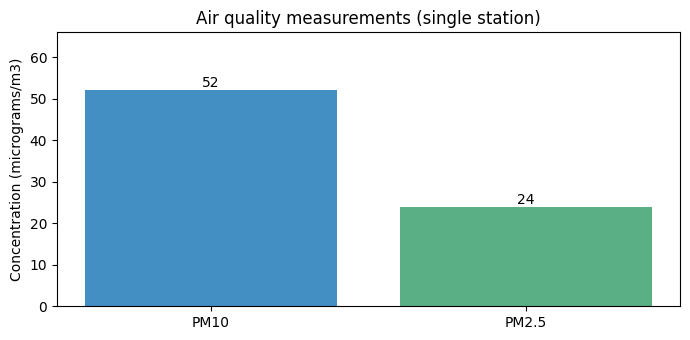

In [6]:
# 두 항목의 농도를 막대그래프로 비교합니다.
# PM10과 PM2.5의 입자 특성·기준이 다르므로 숫자 크기만으로 위험성을 비교하지 않습니다.
import matplotlib.pyplot as plt  # 간단한 그래프를 그리는 도구

그래프자료 = 보고표.dropna(subset=["농도(㎍/㎥)"])  # 측정값 없는 행은 제외합니다.
if 그래프자료.empty:
    print("그릴 수 있는 측정값이 없습니다.")
else:
    # 영문 항목명을 사용해 Colab 환경에서 한글 폰트 깨짐을 피합니다.
    항목이름 = ["PM10" if "PM10" in 이름 else "PM2.5" for 이름 in 그래프자료["항목"]]
    plt.figure(figsize=(7, 3.5))  # 그래프의 가로·세로 크기를 정합니다.
    막대 = plt.bar(항목이름, 그래프자료["농도(㎍/㎥)"], color=["#438FC4", "#5BAF85"][:len(항목이름)])
    plt.title("Air quality measurements (single station)")
    plt.ylabel("Concentration (micrograms/m3)")  # 세로축 단위를 표시합니다.
    for 사각형 in 막대:
        높이 = 사각형.get_height()  # 막대의 높이(농도)를 구합니다.
        plt.text(사각형.get_x() + 사각형.get_width() / 2, 높이, f"{높이:g}", ha="center", va="bottom")
    plt.ylim(0, max(그래프자료["농도(㎍/㎥)"]) * 1.25 + 1)
    plt.tight_layout()  # 글자가 잘리지 않도록 여백을 조정합니다.
    plt.show()

## STEP 7. 보고서를 CSV 파일로 저장하기

CSV는 엑셀에서 열 수 있는 간단한 표 파일입니다. Colab의 왼쪽 **파일** 메뉴에서 내려받을 수 있습니다.

In [7]:
# 저장할 파일 이름에 실행 모드를 넣어 가상/실제 결과를 구분합니다.
파일이름 = f"미세먼지_보고표_{실행모드}.csv"

# utf-8-sig는 엑셀에서 한글이 깨지는 문제를 줄여 줍니다.
보고표.to_csv(파일이름, index=False, encoding="utf-8-sig")
print("✅ CSV 파일 저장 완료:", 파일이름)

# Colab에서 바로 다운로드하려면 아래 두 줄의 주석(#)을 제거합니다.
# from google.colab import files
# files.download(파일이름)

✅ CSV 파일 저장 완료: 미세먼지_보고표_연습.csv


## STEP 8. 결과 검증과 마무리

✅ 실무에서는 **출처·측정소·측정 시각·단위·결측값**을 꼭 확인해야 합니다. 관측값은 예보가 아니며, API 자료의 갱신이 지연될 수도 있습니다.

In [8]:
# 응답 원본에 최신 항목이 있는지, 표의 행 수가 예상과 같은지 확인합니다.
assert len(보고표) == 2, "보고표는 PM10과 PM2.5 두 줄이어야 합니다."
assert "측정시각" in 보고표.columns, "측정 시각이 빠졌습니다."

# 농도값이 있을 때 음수가 아닌지도 확인합니다.
for 농도 in (미세먼지, 초미세먼지):
    assert 농도 is None or 농도 >= 0, "농도에 음수가 있어 원본 확인이 필요합니다."

print("✅ 데이터 구조 및 기본 검사 완료")
print("※ 정상 검사 결과가 '실시간 정보가 정확하다'는 의미는 아닙니다.")

✅ 데이터 구조 및 기본 검사 완료
※ 정상 검사 결과가 '실시간 정보가 정확하다'는 의미는 아닙니다.


## ✍️ 직접 해보기 — 연습문제 3개

1. **초급:** 연습응답에서 `"pm10Value": "52"`를 `"90"`으로 바꾸고 **STEP 3부터 다시 실행**하세요. PM10 등급과 안내문은 어떻게 달라지나요?
2. **초급:** `"pm25Value": "24"`를 `"-"`로 바꾸세요. 프로그램이 **0이 아닌 데이터 없음**으로 처리하는지 확인하세요.
3. **도전:** 공공데이터포털에서 인증키를 발급받고 `실행모드 = "실제"`로 바꾼 뒤 **실제 측정소 이름**으로 조회하세요. 관측 시각과 에어코리아 웹사이트의 표시 값을 비교하세요. 인증키는 제출하지 않습니다.

### 오늘 배운 내용

- **요청:** API 주소와 항목을 서버에 전달합니다.
- **응답:** 서버가 JSON 형태의 데이터를 돌려줍니다.
- **추출:** 전체 응답 중 PM10·PM2.5·측정시각만 가져옵니다.
- **활용:** 구간 안내와 표·그래프·CSV로 바꿉니다.
- **검증:** 가상/실제 자료를 구분하고 결측값·측정 시각을 점검합니다.

**강의 연결:** 10장 17~24쪽의 5단계 실습 및 검증 내용을 Colab 환경에 적용했습니다.
